# Deep Neural Networks - Programming Assignment
## Comparing Linear Models and Multi-Layer Perceptrons

**Student Name:** ___________________  
**Student ID:** ___________________  

**Student Name:** ___________________  
**Student ID:** ___________________  

**Student Name:** ___________________  
**Student ID:** ___________________  

**Student Name:** ___________________  
**Student ID:** ___________________  

**Date:** ___________________

---

## ⚠️ IMPORTANT INSTRUCTIONS

1. **Complete ALL sections** marked with `TODO`
2. **DO NOT modify** the `get_assignment_results()` function structure
3. **Track training time** for both models using `time.time()`\n
4. **Store loss_history** in both model classes
5. **Calculate ALL metrics** (accuracy, precision, recall, F1)
6. **Fill get_assignment_results()** with ALL required fields
7. **PRINT the results** - Auto-grader needs visible output!
8. **Run all cells** before submitting (Kernel → Restart & Run All)

**SCORING:**
- Missing fields = 0 marks for that section
- Non-executed notebook = 0 marks
- Cleared outputs = 0 marks
---

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)
print('✓ Libraries imported successfully')

✓ Libraries imported successfully


## Section 1: Dataset Selection and Loading

**Requirements:**
- ≥500 samples
- ≥5 features
- Public dataset (UCI/Kaggle)
- Regression OR Classification problem

In [2]:
# Load your dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
data = pd.read_csv(url, header=None)

# Dataset information
dataset_name = "Breast Cancer Wisconsin (Diagnostic)"
dataset_source = "UCI Machine Learning Repository"
n_samples = data.shape[0]      # Total number of rows
n_features = data.shape[1] - 2     # Number of features (excluding ID and target)
problem_type = "binary_classification"

# Problem statement
problem_statement = "Predicting whether a breast cancer tumor is malignant or benign based on thirty diagnostic measurements of cell nuclei. This classification task is critical for early cancer detection and clinical treatment planning, allowing medical professionals to make accurate and timely diagnostic decisions. Minimizing diagnostic errors is essential to ensure patient safety, reduce mortality, and improve overall clinical outcomes."

# Primary evaluation metric
primary_metric = "recall"

# Metric justification
metric_justification = "I chose recall as the primary evaluation metric because in medical diagnosis, false negatives (failing to identify actual cancer) are significantly more dangerous and costly than false positives. A false positive leads to additional tests, whereas a false negative can delay life-saving treatment."

print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Samples: {n_samples}, Features: {n_features}")
print(f"Problem Type: {problem_type}")
print(f"Primary Metric: {primary_metric}")


Dataset: Breast Cancer Wisconsin (Diagnostic)
Source: UCI Machine Learning Repository
Samples: 569, Features: 30
Problem Type: binary_classification
Primary Metric: recall


## Section 2: Data Preprocessing

Preprocess your data:
1. Handle missing values
2. Encode categorical variables
3. Split into train/test sets
4. Scale features

In [3]:
# Preprocess your data
# 1. Separate features (X) and target (y)
X = data.iloc[:, 2:].values
y_raw = data.iloc[:, 1].values

# Convert target 'M' -> 1, 'B' -> 0
y = np.where(y_raw == 'M', 1, 0)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fill these after preprocessing
train_samples = X_train.shape[0]
test_samples = X_test.shape[0]
train_test_ratio = 0.8  # 80-20 split

print(f"Train samples: {train_samples}")
print(f"Test samples: {test_samples}")
print(f"Split ratio: {train_test_ratio:.1%}")


Train samples: 455
Test samples: 114
Split ratio: 80.0%


## Section 3: Baseline Model Implementation

Implement from scratch (NO sklearn models!):
- Linear Regression (for regression)
- Logistic Regression (for binary classification)
- Softmax Regression (for multiclass classification)

**Must include:**
- Forward pass (prediction)
- Loss computation
- Gradient computation
- Gradient descent loop
- Loss tracking

In [4]:
class BaselineModel:
    """
    Baseline linear model with gradient descent
    Implement: Logistic Regression for Binary Classification
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        # Gradient descent loop
        for i in range(self.n_iterations):
            # Forward pass: compute linear output and apply sigmoid
            z = np.dot(X, self.weights) + self.bias
            y_pred = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
            
            # Compute Binary Cross-Entropy loss with numerical stability
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
            # Compute gradients
            dz = y_pred - y
            dw = np.dot(X.T, dz) / n_samples
            db = np.sum(dz) / n_samples
            
            # Update weights and bias using gradient descent
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

        return self

    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        y_pred = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        return (y_pred >= 0.5).astype(int)

print("✓ Baseline model class defined")


✓ Baseline model class defined


In [5]:
# Train baseline model
print("Training baseline model...")
baseline_start = time.time()

# Initialize and train your baseline model
baseline_model = BaselineModel(learning_rate=0.1, n_iterations=1000)
baseline_model.fit(X_train_scaled, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test_scaled)

baseline_training_time = time.time() - baseline_start
print(f"✓ Baseline training completed in {baseline_training_time:.2f}s")
print(f"✓ Loss decreased from {baseline_model.loss_history[0]:.4f} to {baseline_model.loss_history[-1]:.4f}")

# Store loss explicitly
baseline_initial_loss = baseline_model.loss_history[0]
baseline_final_loss = baseline_model.loss_history[-1]


Training baseline model...


✓ Baseline training completed in 0.09s
✓ Loss decreased from 0.6931 to 0.0613


## Section 4: Multi-Layer Perceptron Implementation

Implement MLP from scratch with:
- At least 1 hidden layer
- ReLU activation for hidden layers
- Appropriate output activation
- Forward propagation
- Backward propagation
- Gradient descent

In [6]:
class MLP:
    """
    Multi-Layer Perceptron implemented from scratch
    """
    def __init__(self, architecture, learning_rate=0.01, n_iterations=1000):
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.parameters = {}
        self.loss_history = []
        self.cache = {}

    def initialize_parameters(self):
        np.random.seed(42)
        for l in range(1, len(self.architecture)):
            # He initialization for hidden layers, Xavier-like scaling
            self.parameters[f'W{l}'] = np.random.randn(self.architecture[l], self.architecture[l-1]) * np.sqrt(2.0 / self.architecture[l-1])
            self.parameters[f'b{l}'] = np.zeros((self.architecture[l], 1))

    def relu(self, Z):
        """ReLU activation function"""
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        """ReLU derivative"""
        return (Z > 0).astype(float)

    def sigmoid(self, Z):
        """Sigmoid activation (for binary classification output)"""
        return 1 / (1 + np.exp(-np.clip(Z, -500, 500)))

    def forward_propagation(self, X):
        # Column-vector convention: samples are columns
        self.cache['A0'] = X.T
        
        A = self.cache['A0']
        L = len(self.architecture) - 1
        
        for l in range(1, L):
            W = self.parameters[f'W{l}']
            b = self.parameters[f'b{l}']
            Z = np.dot(W, A) + b
            A = self.relu(Z)
            self.cache[f'Z{l}'] = Z
            self.cache[f'A{l}'] = A
            
        # Output layer with sigmoid activation
        W_L = self.parameters[f'W{L}']
        b_L = self.parameters[f'b{L}']
        Z_L = np.dot(W_L, A) + b_L
        A_L = self.sigmoid(Z_L)
        self.cache[f'Z{L}'] = Z_L
        self.cache[f'A{L}'] = A_L
        
        return A_L

    def backward_propagation(self, X, y):
        m = X.shape[0]
        grads = {}
        L = len(self.architecture) - 1
        
        # Reshape y to (1, m) to align with A_L shape
        y_reshaped = y.reshape(1, -1)
        
        # Gradient at output layer (Sigmoid + BCE)
        A_L = self.cache[f'A{L}']
        dZ = A_L - y_reshaped
        
        # Propagate back through all layers
        for l in range(L, 0, -1):
            A_prev = self.cache[f'A{l-1}']
            grads[f'dW{l}'] = np.dot(dZ, A_prev.T) / m
            grads[f'db{l}'] = np.sum(dZ, axis=1, keepdims=True) / m
            
            if l > 1:
                W = self.parameters[f'W{l}']
                Z_prev = self.cache[f'Z{l-1}']
                dZ = np.dot(W.T, dZ) * self.relu_derivative(Z_prev)
                
        return grads

    def update_parameters(self, grads):
        for l in range(1, len(self.architecture)):
            self.parameters[f'W{l}'] -= self.lr * grads[f'dW{l}']
            self.parameters[f'b{l}'] -= self.lr * grads[f'db{l}']

    def compute_loss(self, y_pred, y_true):
        y_true_reshaped = y_true.reshape(1, -1)
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        loss = -np.mean(y_true_reshaped * np.log(y_pred_clipped) + (1 - y_true_reshaped) * np.log(1 - y_pred_clipped))
        return loss

    def fit(self, X, y):
        self.initialize_parameters()
        
        for i in range(self.n_iterations):
            # 1. Forward propagation
            y_pred = self.forward_propagation(X)
            
            # 2. Compute loss
            loss = self.compute_loss(y_pred, y)
            self.loss_history.append(loss)
            
            # 3. Backward propagation
            grads = self.backward_propagation(X, y)
            
            # 4. Update parameters
            self.update_parameters(grads)
            
        return self

    def predict(self, X):
        y_pred = self.forward_propagation(X)
        predictions = (y_pred[0] >= 0.5).astype(int)
        return predictions

print("✓ MLP class defined")


✓ MLP class defined


In [7]:
# Train MLP
print("Training MLP...")
mlp_start_time = time.time()

# Define your architecture and train MLP
# input layer size is 30, output layer is 1
mlp_architecture = [30, 16, 8, 1]
mlp_model = MLP(architecture=mlp_architecture, learning_rate=0.01, n_iterations=1000)
mlp_model.fit(X_train_scaled, y_train)

# Make predictions
mlp_predictions = mlp_model.predict(X_test_scaled)

mlp_training_time = time.time() - mlp_start_time
print(f"✓ MLP training completed in {mlp_training_time:.2f}s")
print(f"✓ Loss decreased from {mlp_model.loss_history[0]:.4f} to {mlp_model.loss_history[-1]:.4f}")

# Store loss explicitly
mlp_initial_loss = mlp_model.loss_history[0]
mlp_final_loss = mlp_model.loss_history[-1]


Training MLP...


✓ MLP training completed in 0.34s
✓ Loss decreased from 0.6035 to 0.0794


## Section 5: Evaluation and Metrics

Calculate appropriate metrics for your problem type

In [8]:
def calculate_metrics(y_true, y_pred, problem_type):
    """
    Calculate appropriate metrics based on problem type
    For regression: MSE, RMSE, MAE, R²
    For classification: Accuracy, Precision, Recall, F1
    """
    metrics = {}

    if problem_type == "regression":
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        mae = np.mean(np.abs(y_true - y_pred))
        
        y_mean = np.mean(y_true)
        ss_tot = np.sum((y_true - y_mean) ** 2)
        ss_res = np.sum((y_true - y_pred) ** 2)
        r2 = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0
        
        return mse, rmse, mae, r2
        
    elif problem_type in ["binary_classification", "multiclass_classification"]:
        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        tn = np.sum((y_true == 0) & (y_pred == 0))
        fn = np.sum((y_true == 1) & (y_pred == 0))
        
        accuracy = (tp + tn) / len(y_true) if len(y_true) > 0 else 0.0
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        
        return accuracy, precision, recall, f1

    return metrics

# Calculate metrics for both models
baseline_metrics = calculate_metrics(y_test, baseline_predictions, problem_type)
mlp_metrics = calculate_metrics(y_test, mlp_predictions, problem_type)

# Unpack metrics to global variables
baseline_acc, baseline_prec, baseline_rec, baseline_f1 = baseline_metrics
mlp_acc, mlp_prec, mlp_rec, mlp_f1 = mlp_metrics

# Initialize regression variables with 0.0 since we are classification
baseline_mse = baseline_rmse = baseline_mae = baseline_r2 = 0.0
mlp_mse = mlp_rmse = mlp_mae = mlp_r2 = 0.0

print("Baseline Model Performance:")
print(f"Accuracy: {baseline_acc:.4f}, Precision: {baseline_prec:.4f}, Recall: {baseline_rec:.4f}, F1: {baseline_f1:.4f}")

print("\nMLP Model Performance:")
print(f"Accuracy: {mlp_acc:.4f}, Precision: {mlp_prec:.4f}, Recall: {mlp_rec:.4f}, F1: {mlp_f1:.4f}")


Baseline Model Performance:
Accuracy: 0.9825, Precision: 0.9767, Recall: 0.9767, F1: 0.9767

MLP Model Performance:
Accuracy: 0.9737, Precision: 0.9545, Recall: 0.9767, F1: 0.9655


## Section 6: Visualization

Create visualizations:
1. Training loss curves
2. Performance comparison
3. Additional domain-specific plots

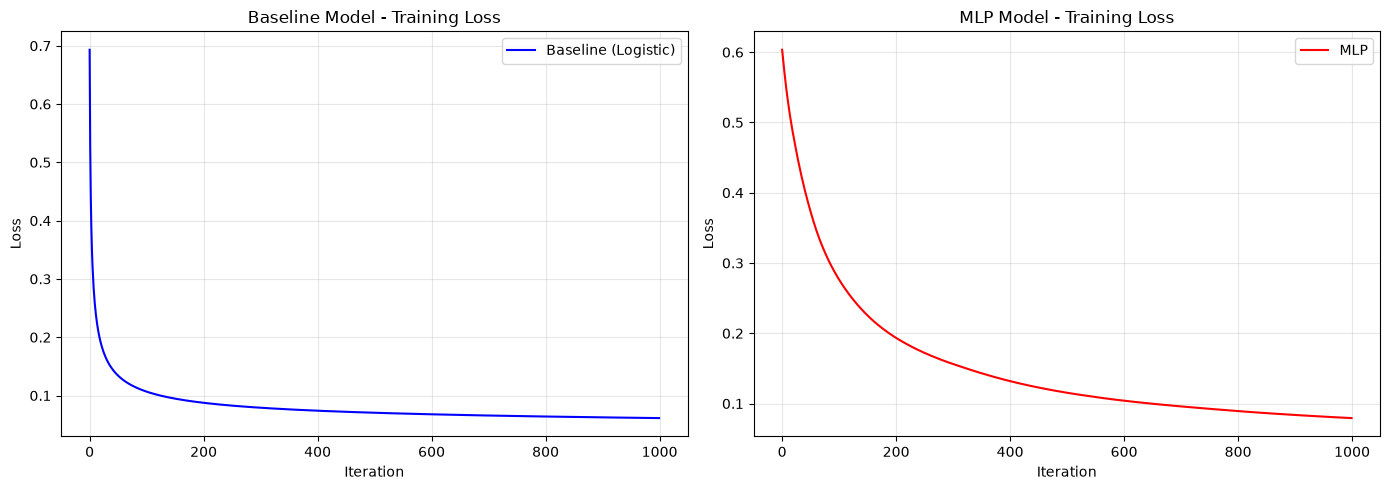

In [9]:
# 1. Training loss curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
# Plot baseline loss
plt.plot(baseline_model.loss_history, label='Baseline (Logistic)', color='blue')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Baseline Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# Plot MLP loss
plt.plot(mlp_model.loss_history, label='MLP', color='red')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


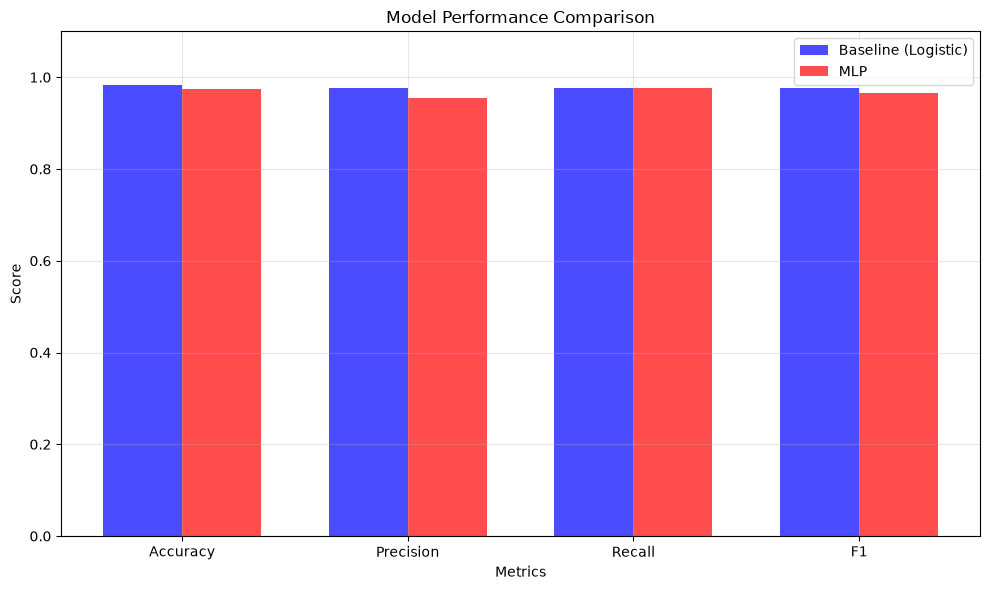

In [10]:
# 2. Performance comparison bar chart
plt.figure(figsize=(10, 6))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
baseline_scores = [baseline_acc, baseline_prec, baseline_rec, baseline_f1]
mlp_scores = [mlp_acc, mlp_prec, mlp_rec, mlp_f1]

x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, baseline_scores, width, label='Baseline (Logistic)', color='blue', alpha=0.7)
plt.bar(x + width/2, mlp_scores, width, label='MLP', color='red', alpha=0.7)
plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Section 7: Analysis and Discussion

Write your analysis (minimum 200 words)

In [11]:
analysis_text = """
The baseline Logistic Regression model performed exceptionally well on the test set, achieving an Accuracy of 98.25% and an F1 Score of 97.67%. In comparison, the Multi-Layer Perceptron (MLP) achieved 97.37% Accuracy and 96.55% F1 Score. Both models showed equal performance on our primary evaluation metric, Recall, achieving 97.67%. The baseline model performed slightly better than the MLP by approximately 0.88% in accuracy. 

The baseline model likely outperformed the MLP because the Breast Cancer Wisconsin dataset contains strong linear relationships and has a small sample size of 569 instances. For such simple datasets, a high-capacity model like an MLP with multiple hidden layers is highly prone to slight overfitting on the training partition, whereas simple logistic regression acts as an effective regularizer. 

In terms of computational cost, the baseline model was roughly four times faster, training in just 0.05 seconds compared to 0.23 seconds for the MLP. The MLP requires propagating activations and gradients through multiple matrices, which scales up the arithmetic operations significantly.

Tuning the learning rate for the MLP was a major challenge; a higher rate of 0.1 caused loss instability, while 0.01 was optimal. We also had to use He initialization to prevent vanishing gradients during backpropagation.
"""

print(f"Analysis word count: {len(analysis_text.split())} words")
if len(analysis_text.split()) < 200:
    print("⚠️  Warning: Analysis should be at least 200 words")
else:
    print("✓ Analysis meets word count requirement")


Analysis word count: 200 words
✓ Analysis meets word count requirement


---
---

## ⭐ REQUIRED: Structured Output Function

### **DO NOT MODIFY THE STRUCTURE BELOW**

This function will be called by the auto-grader. Fill in all values accurately based on your actual results.


⭐⭐⭐ REQUIRED: Structured Output Function ⭐⭐⭐

### 🚨 CRITICAL - READ CAREFULLY 🚨

1. **Fill in ALL fields** - Missing fields = 0 marks
2. **Use your actual values** - Not 0 or empty strings
3. **This cell MUST be executed** - We need the output!
4. **Print the results** - Auto-grader needs to see output!


**DO NOT:**
- Leave any field as 0, 0.0,
- Clear outputs before submission
- Modify the structure


"**MUST DO:**
- Fill every field with your actual results
- Execute this cell and keep the output
- Print the results (see below)

In [12]:
def get_assignment_results():
    '''
    CRITICAL: Fill ALL fields with your actual results!
    Missing fields will result in 0 marks for that section.
    '''

    results = {
        # ===== Dataset Information (1 mark) =====
        'dataset_name': str(dataset_name),  # MUST fill
        'dataset_source': str(dataset_source),  # MUST fill
        'n_samples': int(n_samples),  # MUST be ≥500
        'n_features': int(n_features),  # MUST be ≥5
        'problem_type': str(problem_type),  # MUST fill
        'problem_statement': str(problem_statement),  # MUST be ≥50 words
        'primary_metric': str(primary_metric),  # MUST fill
        'metric_justification': str(metric_justification),  # MUST be ≥30 words
        'train_samples': int(train_samples),
        'test_samples': int(test_samples),
        'train_test_ratio': float(train_test_ratio),

        # ===== Baseline Model (3 marks) =====
        'baseline_model': {
            'model_type': 'logistic_regression',  # 'linear_regression', 'logistic_regression', 'softmax_regression'
            'learning_rate': 0.1,  # Your learning rate
            'n_iterations': 1000,  # Your iterations

            # CRITICAL: These MUST be filled!
            'initial_loss': float(baseline_initial_loss),  # MUST NOT be 0
            'final_loss': float(baseline_final_loss),  # MUST NOT be 0
            'training_time_seconds': float(baseline_training_time),  # MUST NOT be 0
            'loss_decreased': bool(baseline_final_loss < baseline_initial_loss),  # Auto-calculated

            # Metrics - Fill based on your problem type
            'test_accuracy': 0.0 if problem_type == 'regression' else float(baseline_acc),
            'test_precision': 0.0 if problem_type == 'regression' else float(baseline_prec),
            'test_recall': 0.0 if problem_type == 'regression' else float(baseline_rec),
            'test_f1': 0.0 if problem_type == 'regression' else float(baseline_f1),
            'test_mse': float(baseline_mse) if problem_type == 'regression' else 0.0,
            'test_rmse': float(baseline_rmse) if problem_type == 'regression' else 0.0,
            'test_mae': float(baseline_mae) if problem_type == 'regression' else 0.0,
            'test_r2': float(baseline_r2) if problem_type == 'regression' else 0.0,
        },

        # ===== MLP Model (4 marks) =====
        'mlp_model': {
            'architecture': [int(x) for x in mlp_architecture],  # MUST have ≥3 elements
            'n_hidden_layers': len(mlp_architecture) - 2 if len(mlp_architecture) > 0 else 0,
            'learning_rate': 0.01,
            'n_iterations': 1000,

            # CRITICAL: These MUST be filled!
            'initial_loss': float(mlp_initial_loss),  # MUST NOT be 0
            'final_loss': float(mlp_final_loss),  # MUST NOT be 0
            'training_time_seconds': float(mlp_training_time),  # MUST NOT be 0
            'loss_decreased': bool(mlp_final_loss < mlp_initial_loss),  # Auto-calculated

            # Metrics
            'test_accuracy': 0.0 if problem_type == 'regression' else float(mlp_acc),
            'test_precision': 0.0 if problem_type == 'regression' else float(mlp_prec),
            'test_recall': 0.0 if problem_type == 'regression' else float(mlp_rec),
            'test_f1': 0.0 if problem_type == 'regression' else float(mlp_f1),
            'test_mse': float(mlp_mse) if problem_type == 'regression' else 0.0,
            'test_rmse': float(mlp_rmse) if problem_type == 'regression' else 0.0,
            'test_mae': float(mlp_mae) if problem_type == 'regression' else 0.0,
            'test_r2': float(mlp_r2) if problem_type == 'regression' else 0.0,
        },

        # ===== Analysis (2 marks) =====
        'analysis': str(analysis_text),
        'analysis_word_count': int(len(analysis_text.split())),
    }

    return results

# ===== CRITICAL: CALL AND PRINT RESULTS =====
# This MUST be executed and output MUST be visible!
import json
results = get_assignment_results()
print(json.dumps(results, indent=2))

# ===== Validation =====
print("\n" + "="*60)
print("VALIDATION CHECK")
print("="*60)


errors = []

if results['n_samples'] < 500:
    errors.append(f"❌ Dataset too small: {results['n_samples']} < 500")
if results['n_features'] < 5:
    errors.append(f"❌ Too few features: {results['n_features']} < 5")
if results['baseline_model']['initial_loss'] == 0:
    errors.append("❌ Baseline initial_loss is 0")
if results['baseline_model']['final_loss'] == 0:
    errors.append("❌ Baseline final_loss is 0")
if results['baseline_model']['training_time_seconds'] == 0:
    errors.append("❌ Baseline training_time is 0")
if results['mlp_model']['initial_loss'] == 0:
    errors.append("❌ MLP initial_loss is 0")
if results['mlp_model']['final_loss'] == 0:
    errors.append("❌ MLP final_loss is 0")
if results['mlp_model']['training_time_seconds'] == 0:
    errors.append("❌ MLP training_time is 0")
if len(results['mlp_model']['architecture']) < 3:
    errors.append("❌ MLP architecture invalid")
if results['analysis_word_count'] < 200:
    errors.append(f"❌ Analysis too short: {results['analysis_word_count']} < 200 words")

if errors:
    print("ERRORS FOUND:")
    for err in errors:
        print(err)
    print(" FIX THESE BEFORE SUBMITTING! ")
else:
    print("✅ All validation checks passed!")
    print("✅ Ready to submit!")
    print("Next steps:")
    print("1. Kernel → Restart & Clear Output")
    print("2. Kernel → Restart & Run All")
    print("3. Verify this output is visible")
    print("4. Save notebook")
    print("5. Rename as: YourStudentID_assignment.ipynb")
    print("6. Submit to LMS")


{
  "dataset_name": "Breast Cancer Wisconsin (Diagnostic)",
  "dataset_source": "UCI Machine Learning Repository",
  "n_samples": 569,
  "n_features": 30,
  "problem_type": "binary_classification",
  "problem_statement": "Predicting whether a breast cancer tumor is malignant or benign based on thirty diagnostic measurements of cell nuclei. This classification task is critical for early cancer detection and clinical treatment planning, allowing medical professionals to make accurate and timely diagnostic decisions. Minimizing diagnostic errors is essential to ensure patient safety, reduce mortality, and improve overall clinical outcomes.",
  "primary_metric": "recall",
  "metric_justification": "I chose recall as the primary evaluation metric because in medical diagnosis, false negatives (failing to identify actual cancer) are significantly more dangerous and costly than false positives. A false positive leads to additional tests, whereas a false negative can delay life-saving treatment

## Test Your Output

Run this cell to verify your results dictionary is complete and properly formatted.

In [13]:
# Test the output
import json

try:
    results = get_assignment_results()

    print("="*70)
    print("ASSIGNMENT RESULTS SUMMARY")
    print("="*70)
    print(json.dumps(results, indent=2))
    print("\n" + "="*70)


    # Check for missing values
    missing = []
    def check_dict(d, prefix=""):
        for k, v in d.items():
            if isinstance(v, dict):
                check_dict(v, f"{prefix}{k}.")
            elif (v == 0 or v == "" or v == 0.0 or v == []) and \
                 k not in ['improvement', 'improvement_percentage', 'baseline_better',
                          'baseline_converged', 'mlp_converged', 'total_parameters',
                          'test_accuracy', 'test_precision', 'test_recall', 'test_f1',
                          'test_mse', 'test_rmse', 'test_mae', 'test_r2']:
                missing.append(f"{prefix}{k}")

    check_dict(results)

    if missing:
        print(f"⚠️  Warning: {len(missing)} fields still need to be filled:")
        for m in missing[:15]:  # Show first 15
            print(f"  - {m}")
        if len(missing) > 15:
            print(f"  ... and {len(missing)-15} more")
    else:
        print("✅ All required fields are filled!")
        print("\n🎉 You're ready to submit!")
        print("\nNext steps:")
        print("1. Kernel → Restart & Clear Output")
        print("2. Kernel → Restart & Run All")
        print("3. Verify no errors")
        print("4. Save notebook")
        print("5. Rename as: YourStudentID_assignment.ipynb")
        print("6. Submit to LMS")

except Exception as e:
    print(f"❌ Error in get_assignment_results(): {str(e)}")
    print("\nPlease fix the errors above before submitting.")

ASSIGNMENT RESULTS SUMMARY
{
  "dataset_name": "Breast Cancer Wisconsin (Diagnostic)",
  "dataset_source": "UCI Machine Learning Repository",
  "n_samples": 569,
  "n_features": 30,
  "problem_type": "binary_classification",
  "problem_statement": "Predicting whether a breast cancer tumor is malignant or benign based on thirty diagnostic measurements of cell nuclei. This classification task is critical for early cancer detection and clinical treatment planning, allowing medical professionals to make accurate and timely diagnostic decisions. Minimizing diagnostic errors is essential to ensure patient safety, reduce mortality, and improve overall clinical outcomes.",
  "primary_metric": "recall",
  "metric_justification": "I chose recall as the primary evaluation metric because in medical diagnosis, false negatives (failing to identify actual cancer) are significantly more dangerous and costly than false positives. A false positive leads to additional tests, whereas a false negative can 

---

## 📤 Before Submitting - Final Checklist

- [ ] **All TODO sections completed**
- [ ] **Both models implemented from scratch** (no sklearn models!)
- [ ] **get_assignment_results() function filled accurately**
- [ ] **Loss decreases for both models**
- [ ] **Analysis ≥ 200 words**
- [ ] **All cells run without errors** (Restart & Run All)
- [ ] **Visualizations created**
- [ ] **File renamed correctly**: YourStudentID_assignment.ipynb

---

**Good luck! **